In [1]:
#DELHI AFTER DARK
#Reimagining the City Through Its Points of Interest

POSSIBLE POI FILES
1. C:\Users\Manjar\Desktop\30DaysMap\gis_osm_pois_a_free_1.shp
2. C:\Users\Manjar\Desktop\30DaysMap\gis_osm_pois_free_1.shp

Selected POI file:
C:\Users\Manjar\Desktop\30DaysMap\gis_osm_pois_a_free_1.shp

DELHI POI DATA
Features : 26227
CRS      : EPSG:4326
Geometry :
Polygon         26189
MultiPolygon       38
Name: count, dtype: int64

Fields:
['osm_id', 'code', 'fclass', 'name', 'geometry']

First 5 records:
    osm_id  code         fclass                                            name                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

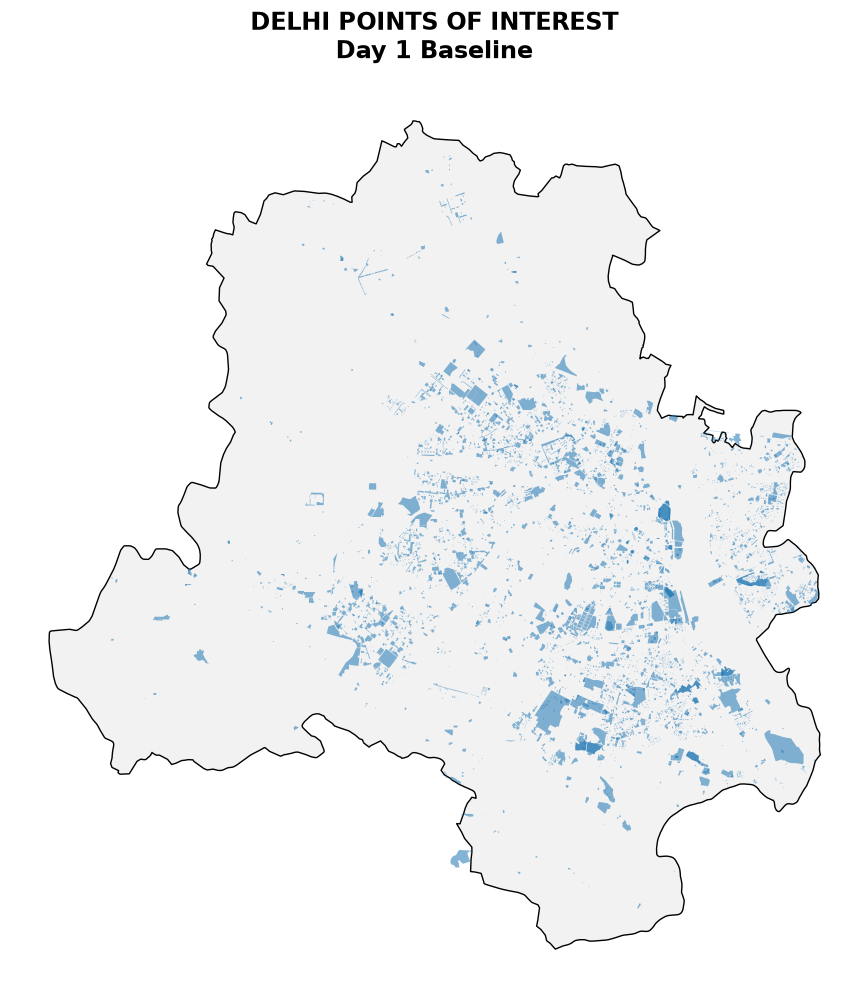


STEP 1 COMPLETE

Working POI dataset:
C:\Users\Manjar\Desktop\30DaysMap\Day30_Makeover\Delhi_POI_Day30.gpkg

Baseline preview:
C:\Users\Manjar\Desktop\30DaysMap\Day30_Makeover\Step1_Day1_POI_Baseline.png


In [3]:
# STEP 1 — FIND AND INSPECT THE ORIGINAL DELHI POI DATA

from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# ---------------------------------------------------------
# Main 30DayMap folder
# ---------------------------------------------------------
base = Path(r"C:\Users\Manjar\Desktop\30DaysMap")

# Delhi boundary
boundary_path = base / "delhi_bound.shp"

# Output folder for Day 30
output = base / "Day30_Makeover"
output.mkdir(exist_ok=True)

# ---------------------------------------------------------
# Find possible OSM POI shapefiles automatically
# ---------------------------------------------------------
poi_files = []

for shp in base.rglob("*.shp"):

    name = shp.name.lower()

    if "poi" in name:
        poi_files.append(shp)

print("=" * 65)
print("POSSIBLE POI FILES")
print("=" * 65)

if len(poi_files) == 0:
    print("No POI shapefile found.")
else:
    for i, path in enumerate(poi_files, start=1):
        print(f"{i}. {path}")

# ---------------------------------------------------------
# Select likely OSM POI file
# ---------------------------------------------------------
preferred = [
    p for p in poi_files
    if "gis_osm_pois" in p.name.lower()
]

if preferred:
    poi_path = preferred[0]

elif poi_files:
    poi_path = poi_files[0]

else:
    raise FileNotFoundError(
        "No POI shapefile was found inside the 30DaysMap folder."
    )

print("\nSelected POI file:")
print(poi_path)

# ---------------------------------------------------------
# Read data
# ---------------------------------------------------------
pois = gpd.read_file(poi_path)
delhi = gpd.read_file(boundary_path)

print("\n" + "=" * 65)
print("DELHI POI DATA")
print("=" * 65)

print("Features :", len(pois))
print("CRS      :", pois.crs)
print("Geometry :")
print(pois.geom_type.value_counts())

print("\nFields:")
print(list(pois.columns))

print("\nFirst 5 records:")
print(pois.head().to_string())

# ---------------------------------------------------------
# Inspect useful categorical fields
# ---------------------------------------------------------
possible_fields = [
    "fclass",
    "type",
    "amenity",
    "name",
    "code"
]

print("\n" + "=" * 65)
print("CATEGORY CHECK")
print("=" * 65)

for field in possible_fields:

    if field in pois.columns:

        print(f"\nFIELD: {field}")
        print("-" * 40)

        print(
            pois[field]
            .fillna("NULL")
            .value_counts()
            .head(30)
            .to_string()
        )

# ---------------------------------------------------------
# Boundary information
# ---------------------------------------------------------
print("\n" + "=" * 65)
print("DELHI BOUNDARY")
print("=" * 65)

print("Features :", len(delhi))
print("CRS      :", delhi.crs)
print("Bounds   :", delhi.total_bounds)

# Match CRS
if pois.crs != delhi.crs:
    pois = pois.to_crs(delhi.crs)

# ---------------------------------------------------------
# Keep only POIs inside Delhi
# ---------------------------------------------------------
delhi_geom = delhi.geometry.union_all()

pois_delhi = pois[
    pois.geometry.intersects(delhi_geom)
].copy()

print("\nPOIs before Delhi filter :", len(pois))
print("POIs inside Delhi        :", len(pois_delhi))

# Save cleaned Day 30 working data
clean_path = output / "Delhi_POI_Day30.gpkg"

pois_delhi.to_file(
    clean_path,
    layer="poi",
    driver="GPKG"
)

# ---------------------------------------------------------
# Simple DAY 1-style baseline preview
# ---------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(9, 10),
    facecolor="white"
)

delhi.plot(
    ax=ax,
    facecolor="#F2F2F2",
    edgecolor="black",
    linewidth=1
)

pois_delhi.plot(
    ax=ax,
    markersize=2,
    alpha=0.55
)

ax.set_title(
    "DELHI POINTS OF INTEREST\nDay 1 Baseline",
    fontsize=17,
    weight="bold",
    pad=15
)

ax.set_axis_off()

plt.tight_layout()

preview_path = output / "Step1_Day1_POI_Baseline.png"

plt.savefig(
    preview_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ---------------------------------------------------------
# Final summary
# ---------------------------------------------------------
print("\n" + "=" * 65)
print("STEP 1 COMPLETE")
print("=" * 65)

print("\nWorking POI dataset:")
print(clean_path)

print("\nBaseline preview:")
print(preview_path)

Delhi POIs : 8164
CRS        : EPSG:4326

DAY 30 POI CATEGORIES
            Category  POIs
  Parks & Recreation  5047
           Education   985
               Other   692
     Public Services   515
  Tourism & Heritage   254
              Health   202
Urban Infrastructure   181
            Shopping   153
        Food & Drink   135

Total classified POIs: 8164


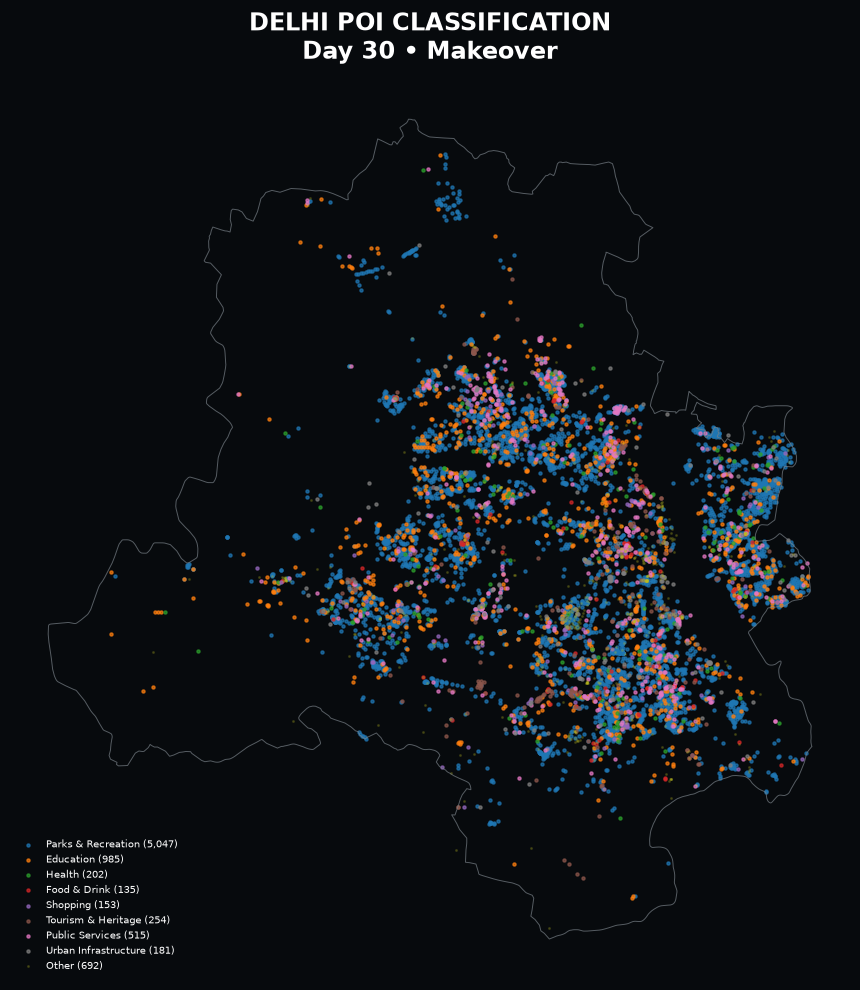


STEP 2 COMPLETE

Classified POIs:
C:\Users\Manjar\Desktop\30DaysMap\Day30_Makeover\Delhi_POI_Classified.gpkg

Preview:
C:\Users\Manjar\Desktop\30DaysMap\Day30_Makeover\Step2_POI_Classification.png


In [4]:
# STEP 2 — CLASSIFY DELHI POIs FOR THE DAY 30 MAKEOVER

from pathlib import Path
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Paths
# ---------------------------------------------------------
base = Path(r"C:\Users\Manjar\Desktop\30DaysMap")
output = base / "Day30_Makeover"

poi_path = output / "Delhi_POI_Day30.gpkg"
boundary_path = base / "delhi_bound.shp"

classified_path = output / "Delhi_POI_Classified.gpkg"

# ---------------------------------------------------------
# Read data
# ---------------------------------------------------------
pois = gpd.read_file(poi_path)
delhi = gpd.read_file(boundary_path)

print("Delhi POIs :", len(pois))
print("CRS        :", pois.crs)

# ---------------------------------------------------------
# Classification groups
# ---------------------------------------------------------
category_map = {

    # Green / recreation
    "park": "Parks & Recreation",
    "pitch": "Parks & Recreation",
    "playground": "Parks & Recreation",
    "swimming_pool": "Parks & Recreation",
    "stadium": "Parks & Recreation",
    "sports_centre": "Parks & Recreation",

    # Education
    "school": "Education",
    "college": "Education",
    "university": "Education",
    "library": "Education",
    "kindergarten": "Education",

    # Health
    "hospital": "Health",
    "clinic": "Health",
    "pharmacy": "Health",
    "doctors": "Health",
    "dentist": "Health",

    # Food
    "restaurant": "Food & Drink",
    "cafe": "Food & Drink",
    "fast_food": "Food & Drink",
    "bar": "Food & Drink",
    "pub": "Food & Drink",

    # Shopping
    "marketplace": "Shopping",
    "mall": "Shopping",
    "supermarket": "Shopping",
    "department_store": "Shopping",
    "convenience": "Shopping",

    # Tourism
    "hotel": "Tourism & Heritage",
    "hostel": "Tourism & Heritage",
    "guesthouse": "Tourism & Heritage",
    "attraction": "Tourism & Heritage",
    "castle": "Tourism & Heritage",
    "fort": "Tourism & Heritage",
    "observation_tower": "Tourism & Heritage",
    "camp_site": "Tourism & Heritage",

    # Public services
    "police": "Public Services",
    "community_centre": "Public Services",
    "toilet": "Public Services",
    "shelter": "Public Services",
    "fire_station": "Public Services",
    "post_office": "Public Services",
    "town_hall": "Public Services",

    # Infrastructure
    "water_tower": "Urban Infrastructure",
    "water_works": "Urban Infrastructure",
    "wastewater_plant": "Urban Infrastructure",
    "fountain": "Urban Infrastructure"
}

# Apply classification
pois["category"] = (
    pois["fclass"]
    .map(category_map)
    .fillna("Other")
)

# ---------------------------------------------------------
# Convert POI areas to representative points
# ---------------------------------------------------------
# EPSG:32643 = suitable projected CRS for Delhi
pois_projected = pois.to_crs("EPSG:32643")

poi_points = pois_projected.copy()

# representative_point() guarantees the point lies within
# its original POI polygon
poi_points["geometry"] = (
    pois_projected.geometry.representative_point()
)

poi_points = poi_points.to_crs("EPSG:4326")

# ---------------------------------------------------------
# Category statistics
# ---------------------------------------------------------
category_counts = (
    poi_points["category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="POIs")
)

print("\n" + "=" * 55)
print("DAY 30 POI CATEGORIES")
print("=" * 55)

print(category_counts.to_string(index=False))

print("\nTotal classified POIs:", len(poi_points))

# Save CSV summary
category_counts.to_csv(
    output / "Day30_POI_Category_Counts.csv",
    index=False
)

# Save classified points
poi_points.to_file(
    classified_path,
    layer="poi",
    driver="GPKG"
)

# ---------------------------------------------------------
# Quick classification preview
# ---------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(10, 10),
    facecolor="#070A0D"
)

ax.set_facecolor("#070A0D")

# Delhi outline
delhi.to_crs("EPSG:4326").boundary.plot(
    ax=ax,
    linewidth=0.7,
    edgecolor="#788087",
    alpha=0.7
)

# Draw each category separately
categories = [
    "Parks & Recreation",
    "Education",
    "Health",
    "Food & Drink",
    "Shopping",
    "Tourism & Heritage",
    "Public Services",
    "Urban Infrastructure",
    "Other"
]

for category in categories:

    subset = poi_points[
        poi_points["category"] == category
    ]

    if len(subset) > 0:

        subset.plot(
            ax=ax,
            markersize=5 if category != "Other" else 1.5,
            alpha=0.70 if category != "Other" else 0.20,
            label=f"{category} ({len(subset):,})"
        )

ax.set_title(
    "DELHI POI CLASSIFICATION\nDay 30 • Makeover",
    color="white",
    fontsize=17,
    weight="bold",
    pad=14
)

legend = ax.legend(
    loc="lower left",
    fontsize=7,
    frameon=False
)

for text in legend.get_texts():
    text.set_color("white")

ax.set_axis_off()

plt.tight_layout()

preview_path = output / "Step2_POI_Classification.png"

plt.savefig(
    preview_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("\n" + "=" * 55)
print("STEP 2 COMPLETE")
print("=" * 55)

print("\nClassified POIs:")
print(classified_path)

print("\nPreview:")
print(preview_path)

DAY 30 — DELHI AFTER DARK

Total POIs : 8164

Category counts:
category
Parks & Recreation      5047
Education                985
Other                    692
Public Services          515
Tourism & Heritage       254
Health                   202
Urban Infrastructure     181
Shopping                 153
Food & Drink             135
Name: count, dtype: int64


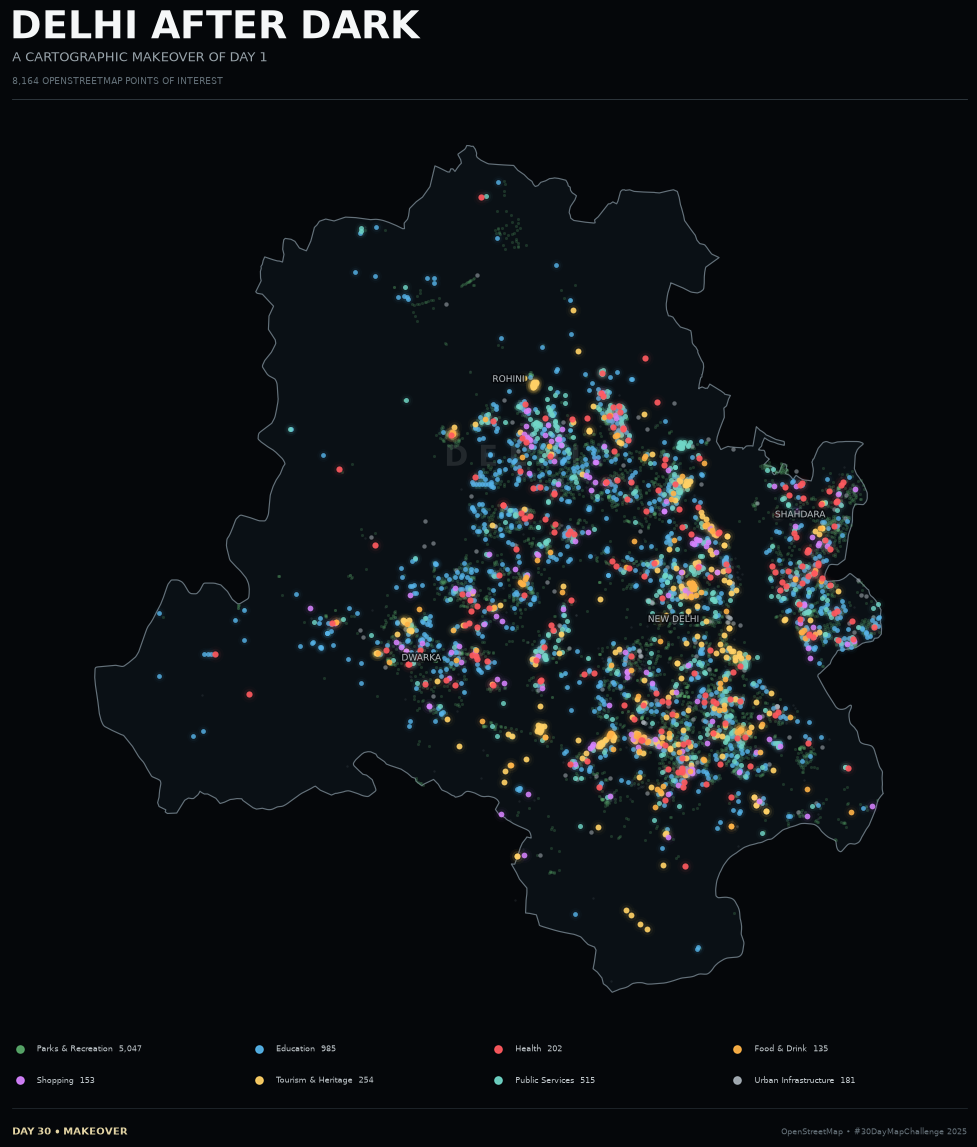


STEP 3 CORRECTED PREVIEW COMPLETE

Saved:
C:\Users\Manjar\Desktop\30DaysMap\Day30_Makeover\Step3_Delhi_After_Dark_Corrected.png

Total POIs: 8,164

Ready for Step 4 — Final 600-DPI Makeover Poster


In [6]:
# STEP 3 — DELHI AFTER DARK
# Complete corrected cartographic preview with separate header

from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe


# =========================================================
# 1. PATHS AND DATA
# =========================================================

base = Path(r"C:\Users\Manjar\Desktop\30DaysMap")
output = base / "Day30_Makeover"
output.mkdir(exist_ok=True)

poi_path = output / "Delhi_POI_Classified.gpkg"
boundary_path = base / "delhi_bound.shp"

preview_path = output / "Step3_Delhi_After_Dark_Corrected.png"

# Read data
pois = gpd.read_file(poi_path)
delhi = gpd.read_file(boundary_path)

# Standardize CRS
pois = pois.to_crs("EPSG:4326")
delhi = delhi.to_crs("EPSG:4326")

print("=" * 60)
print("DAY 30 — DELHI AFTER DARK")
print("=" * 60)

print("\nTotal POIs :", len(pois))

print("\nCategory counts:")
print(pois["category"].value_counts())


# =========================================================
# 2. CARTOGRAPHIC STYLE
# =========================================================

BACKGROUND = "#05070A"
DELHI_FILL = "#0A1015"
DELHI_EDGE = "#64717A"

styles = {

    "Parks & Recreation": {
        "color": "#59A96A",
        "size": 5,
        "alpha": 0.23
    },

    "Education": {
        "color": "#56B4E9",
        "size": 12,
        "alpha": 0.82
    },

    "Health": {
        "color": "#FF5A5F",
        "size": 20,
        "alpha": 0.92
    },

    "Food & Drink": {
        "color": "#FFB347",
        "size": 17,
        "alpha": 0.90
    },

    "Shopping": {
        "color": "#D783FF",
        "size": 17,
        "alpha": 0.88
    },

    "Tourism & Heritage": {
        "color": "#FFD166",
        "size": 18,
        "alpha": 0.92
    },

    "Public Services": {
        "color": "#70D6C7",
        "size": 13,
        "alpha": 0.82
    },

    "Urban Infrastructure": {
        "color": "#A7B0B7",
        "size": 10,
        "alpha": 0.55
    },

    "Other": {
        "color": "#59636B",
        "size": 3,
        "alpha": 0.20
    }
}


# =========================================================
# 3. CREATE FIGURE WITH SEPARATE HEADER + MAP
# =========================================================

fig = plt.figure(
    figsize=(11, 12),
    facecolor=BACKGROUND
)

# ---------------------------------------------------------
# HEADER
# ---------------------------------------------------------

fig.text(
    0.065,
    0.958,
    "DELHI AFTER DARK",
    fontsize=27,
    weight="bold",
    color="#F5F7F8",
    ha="left",
    va="top"
)

fig.text(
    0.067,
    0.923,
    "A CARTOGRAPHIC MAKEOVER OF DAY 1",
    fontsize=9,
    color="#9AA5AC",
    ha="left",
    va="top"
)

fig.text(
    0.067,
    0.902,
    f"{len(pois):,} OPENSTREETMAP POINTS OF INTEREST",
    fontsize=6.7,
    color="#65727A",
    ha="left",
    va="top"
)

# Header separator
fig.add_artist(
    plt.Line2D(
        [0.067, 0.935],
        [0.884, 0.884],
        transform=fig.transFigure,
        linewidth=0.6,
        color="#53616A",
        alpha=0.60
    )
)

# ---------------------------------------------------------
# MAIN MAP AXIS
# ---------------------------------------------------------

ax = fig.add_axes([
    0.055,     # left
    0.115,     # bottom
    0.89,      # width
    0.755      # height
])

ax.set_facecolor(BACKGROUND)

# Delhi base polygon
delhi.plot(
    ax=ax,
    facecolor=DELHI_FILL,
    edgecolor=DELHI_EDGE,
    linewidth=0.85,
    alpha=1.0,
    zorder=1
)


# ---------------------------------------------------------
# GLOW FUNCTION
# ---------------------------------------------------------

def plot_glowing_points(
    ax,
    data,
    color,
    size,
    alpha,
    glow=True,
    zorder=5
):

    if len(data) == 0:
        return

    # Outer glow
    if glow:

        data.plot(
            ax=ax,
            color=color,
            markersize=size * 7,
            alpha=0.025,
            linewidth=0,
            zorder=zorder
        )

        # Middle glow
        data.plot(
            ax=ax,
            color=color,
            markersize=size * 3.5,
            alpha=0.055,
            linewidth=0,
            zorder=zorder + 0.1
        )

    # Core symbol
    data.plot(
        ax=ax,
        color=color,
        markersize=size,
        alpha=alpha,
        linewidth=0,
        zorder=zorder + 0.2
    )


# ---------------------------------------------------------
# DRAW POIs
# ---------------------------------------------------------

draw_order = [
    "Other",
    "Parks & Recreation",
    "Urban Infrastructure",
    "Education",
    "Public Services",
    "Tourism & Heritage",
    "Shopping",
    "Food & Drink",
    "Health"
]

for i, category in enumerate(draw_order):

    subset = pois[
        pois["category"] == category
    ]

    style = styles[category]

    # Background categories don't need glow
    glow = category not in [
        "Other",
        "Parks & Recreation",
        "Urban Infrastructure"
    ]

    plot_glowing_points(
        ax=ax,
        data=subset,
        color=style["color"],
        size=style["size"],
        alpha=style["alpha"],
        glow=glow,
        zorder=4 + i
    )


# ---------------------------------------------------------
# LARGE SUBTLE DELHI LABEL
# ---------------------------------------------------------

ax.text(
    77.105,
    28.705,
    "D E L H I",
    fontsize=21,
    weight="bold",
    color="#FFFFFF",
    alpha=0.10,
    ha="center",
    va="center",
    zorder=2
)


# ---------------------------------------------------------
# SELECTED PLACE LABELS
# ---------------------------------------------------------

place_labels = [

    ("ROHINI", 77.1025, 28.7495),

    ("DWARKA", 77.0460, 28.5921),

    ("NEW DELHI", 77.2090, 28.6139),

    ("SHAHDARA", 77.2900, 28.6730)
]

for name, x, y in place_labels:

    txt = ax.text(
        x,
        y,
        name,
        fontsize=6.5,
        color="#D7DEE2",
        alpha=0.78,
        ha="center",
        va="center",
        zorder=25
    )

    txt.set_path_effects([
        pe.withStroke(
            linewidth=2.5,
            foreground=BACKGROUND
        )
    ])


# ---------------------------------------------------------
# MAP EXTENT
# ---------------------------------------------------------

xmin, ymin, xmax, ymax = delhi.total_bounds

pad_x = (xmax - xmin) * 0.035
pad_y = (ymax - ymin) * 0.035

ax.set_xlim(
    xmin - pad_x,
    xmax + pad_x
)

ax.set_ylim(
    ymin - pad_y,
    ymax + pad_y
)

ax.set_axis_off()


# =========================================================
# 4. LEGEND + FOOTER
# =========================================================

counts = pois["category"].value_counts()

legend_order = [
    "Parks & Recreation",
    "Education",
    "Health",
    "Food & Drink",
    "Shopping",
    "Tourism & Heritage",
    "Public Services",
    "Urban Infrastructure"
]

# Dedicated legend axis
legend_ax = fig.add_axes([
    0.065,
    0.052,
    0.87,
    0.055
])

legend_ax.set_facecolor(BACKGROUND)

legend_ax.set_xlim(0, 1)
legend_ax.set_ylim(0, 1)

legend_ax.axis("off")

# 4 columns × 2 rows
for i, category in enumerate(legend_order):

    row = i // 4
    col = i % 4

    x = 0.01 + col * 0.25
    y = 0.73 - row * 0.48

    style = styles[category]

    legend_ax.scatter(
        x,
        y,
        s=27,
        color=style["color"],
        alpha=0.95
    )

    legend_ax.text(
        x + 0.018,
        y,
        f"{category}  {counts.get(category, 0):,}",
        fontsize=6.0,
        color="#BEC5C9",
        ha="left",
        va="center"
    )


# ---------------------------------------------------------
# FOOTER SEPARATOR
# ---------------------------------------------------------

fig.add_artist(
    plt.Line2D(
        [0.067, 0.935],
        [0.043, 0.043],
        transform=fig.transFigure,
        linewidth=0.5,
        color="#39444A",
        alpha=0.65
    )
)


# ---------------------------------------------------------
# DAY 30
# ---------------------------------------------------------

fig.text(
    0.067,
    0.023,
    "DAY 30 • MAKEOVER",
    fontsize=7.5,
    weight="bold",
    color="#E4D5A5",
    ha="left",
    va="center"
)


# ---------------------------------------------------------
# DATA SOURCE
# ---------------------------------------------------------

fig.text(
    0.935,
    0.023,
    "OpenStreetMap • #30DayMapChallenge 2025",
    fontsize=5.8,
    color="#66727A",
    ha="right",
    va="center"
)


# =========================================================
# 5. SAVE CORRECTED PREVIEW
# =========================================================

plt.savefig(
    preview_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.12,
    facecolor=fig.get_facecolor()
)

plt.show()

print("\n" + "=" * 60)
print("STEP 3 CORRECTED PREVIEW COMPLETE")
print("=" * 60)

print("\nSaved:")
print(preview_path)

print("\nTotal POIs:", f"{len(pois):,}")

print("\nReady for Step 4 — Final 600-DPI Makeover Poster")

Total POIs : 8,164


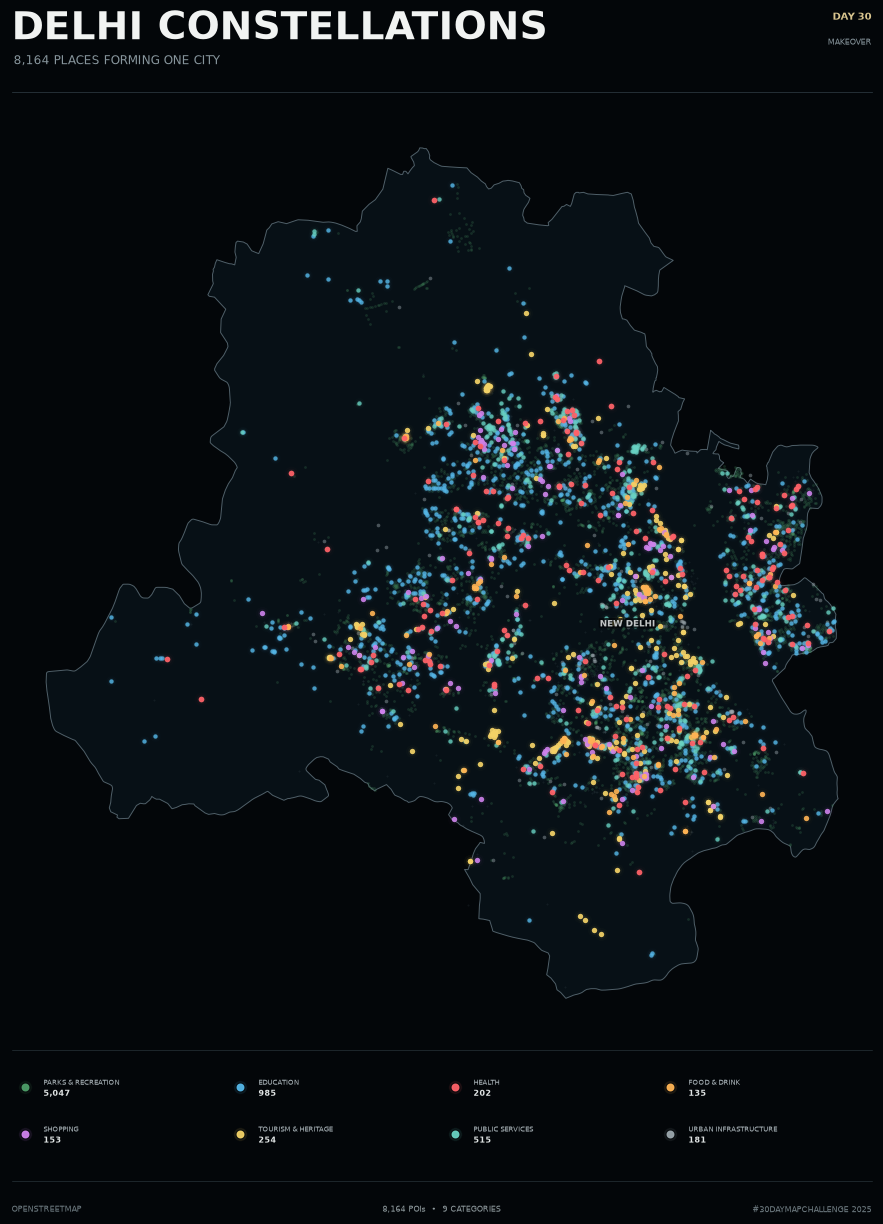


DAY 30 FINAL POSTER COMPLETE

DELHI CONSTELLATIONS
8,164 places forming one city

Output:
C:\Users\Manjar\Desktop\30DaysMap\Day30_Makeover\Day30_Delhi_Constellations_Final.png

Resolution : 600 DPI
Theme      : Makeover
POIs       : 8,164
Categories : 9


In [8]:
# STEP 4 — FINAL 600-DPI POSTER
# DELHI CONSTELLATIONS • DAY 30 MAKEOVER

from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe


# =========================================================
# 1. PATHS + DATA
# =========================================================

base = Path(r"C:\Users\Manjar\Desktop\30DaysMap")
output = base / "Day30_Makeover"
output.mkdir(exist_ok=True)

poi_path = output / "Delhi_POI_Classified.gpkg"
boundary_path = base / "delhi_bound.shp"

final_png = output / "Day30_Delhi_Constellations_Final.png"

# Read data
pois = gpd.read_file(poi_path).to_crs("EPSG:4326")
delhi = gpd.read_file(boundary_path).to_crs("EPSG:4326")

print("Total POIs :", f"{len(pois):,}")


# =========================================================
# 2. CARTOGRAPHIC DESIGN
# =========================================================

BACKGROUND = "#030609"
LAND       = "#071016"
BOUNDARY   = "#506069"
TEXT       = "#F1F3F2"
SUBTEXT    = "#87959C"
GOLD       = "#D9C58F"

# Category styling
styles = {

    "Parks & Recreation": {
        "color": "#4D9D68",
        "size": 4.0,
        "alpha": 0.20,
        "glow": False
    },

    "Education": {
        "color": "#55B7E8",
        "size": 10,
        "alpha": 0.82,
        "glow": True
    },

    "Health": {
        "color": "#FF6268",
        "size": 17,
        "alpha": 0.94,
        "glow": True
    },

    "Food & Drink": {
        "color": "#FFB454",
        "size": 15,
        "alpha": 0.91,
        "glow": True
    },

    "Shopping": {
        "color": "#CF83ED",
        "size": 15,
        "alpha": 0.90,
        "glow": True
    },

    "Tourism & Heritage": {
        "color": "#F3D267",
        "size": 15,
        "alpha": 0.93,
        "glow": True
    },

    "Public Services": {
        "color": "#68D2C3",
        "size": 10,
        "alpha": 0.80,
        "glow": True
    },

    "Urban Infrastructure": {
        "color": "#9BA7AD",
        "size": 7,
        "alpha": 0.45,
        "glow": False
    },

    "Other": {
        "color": "#53616A",
        "size": 2.2,
        "alpha": 0.15,
        "glow": False
    }
}

draw_order = [
    "Other",
    "Parks & Recreation",
    "Urban Infrastructure",
    "Education",
    "Public Services",
    "Tourism & Heritage",
    "Shopping",
    "Food & Drink",
    "Health"
]

counts = pois["category"].value_counts()


# =========================================================
# 3. CREATE POSTER
# =========================================================

fig = plt.figure(
    figsize=(10, 13),
    facecolor=BACKGROUND
)


# ---------------------------------------------------------
# HEADER
# ---------------------------------------------------------

fig.text(
    0.07,
    0.958,
    "DELHI CONSTELLATIONS",
    fontsize=28,
    weight="bold",
    color=TEXT,
    ha="left",
    va="top"
)

fig.text(
    0.072,
    0.923,
    f"{len(pois):,} PLACES FORMING ONE CITY",
    fontsize=8.5,
    color=SUBTEXT,
    ha="left",
    va="top"
)

# Theme on right
fig.text(
    0.93,
    0.956,
    "DAY 30",
    fontsize=7,
    weight="bold",
    color=GOLD,
    ha="right",
    va="top"
)

fig.text(
    0.93,
    0.936,
    "MAKEOVER",
    fontsize=6,
    color=SUBTEXT,
    ha="right",
    va="top"
)

# Header line
fig.add_artist(
    plt.Line2D(
        [0.07, 0.93],
        [0.895, 0.895],
        transform=fig.transFigure,
        linewidth=0.55,
        color="#34434B",
        alpha=0.85
    )
)


# ---------------------------------------------------------
# MAIN MAP
# ---------------------------------------------------------

ax = fig.add_axes([
    0.055,
    0.175,
    0.89,
    0.70
])

ax.set_facecolor(BACKGROUND)

# Delhi base
delhi.plot(
    ax=ax,
    facecolor=LAND,
    edgecolor=BOUNDARY,
    linewidth=0.70,
    alpha=1,
    zorder=1
)


# ---------------------------------------------------------
# GLOW FUNCTION
# ---------------------------------------------------------

def plot_constellation(
    axis,
    data,
    color,
    size,
    alpha,
    glow,
    zorder
):

    if len(data) == 0:
        return

    if glow:

        # Wide faint halo
        data.plot(
            ax=axis,
            color=color,
            markersize=size * 6.0,
            alpha=0.015,
            linewidth=0,
            zorder=zorder
        )

        # Inner halo
        data.plot(
            ax=axis,
            color=color,
            markersize=size * 2.8,
            alpha=0.045,
            linewidth=0,
            zorder=zorder + 0.1
        )

    # Actual POI
    data.plot(
        ax=axis,
        color=color,
        markersize=size,
        alpha=alpha,
        linewidth=0,
        zorder=zorder + 0.2
    )


# ---------------------------------------------------------
# DRAW ALL CATEGORIES
# ---------------------------------------------------------

for i, category in enumerate(draw_order):

    subset = pois[
        pois["category"] == category
    ]

    style = styles[category]

    plot_constellation(
        axis=ax,
        data=subset,
        color=style["color"],
        size=style["size"],
        alpha=style["alpha"],
        glow=style["glow"],
        zorder=3 + i
    )


# ---------------------------------------------------------
# NEW DELHI LABEL ONLY
# ---------------------------------------------------------

label = ax.text(
    77.2090,
    28.6139,
    "NEW DELHI",
    fontsize=6.3,
    weight="bold",
    color="#E7EBEB",
    alpha=0.80,
    ha="center",
    va="center",
    zorder=30
)

label.set_path_effects([
    pe.withStroke(
        linewidth=2.8,
        foreground=BACKGROUND
    )
])


# ---------------------------------------------------------
# MAP EXTENT
# ---------------------------------------------------------

xmin, ymin, xmax, ymax = delhi.total_bounds

dx = xmax - xmin
dy = ymax - ymin

ax.set_xlim(
    xmin - dx * 0.045,
    xmax + dx * 0.045
)

ax.set_ylim(
    ymin - dy * 0.035,
    ymax + dy * 0.035
)

ax.set_axis_off()


# =========================================================
# 4. CLEAN LEGEND
# =========================================================

legend_ax = fig.add_axes([
    0.07,
    0.075,
    0.86,
    0.075
])

legend_ax.set_facecolor(BACKGROUND)
legend_ax.set_xlim(0, 1)
legend_ax.set_ylim(0, 1)
legend_ax.axis("off")


legend_order = [
    "Parks & Recreation",
    "Education",
    "Health",
    "Food & Drink",
    "Shopping",
    "Tourism & Heritage",
    "Public Services",
    "Urban Infrastructure"
]

# 4 columns × 2 rows
for i, category in enumerate(legend_order):

    row = i // 4
    col = i % 4

    x = 0.015 + col * 0.25
    y = 0.72 - row * 0.48

    style = styles[category]

    # Small halo in legend
    legend_ax.scatter(
        x,
        y,
        s=75,
        color=style["color"],
        alpha=0.07
    )

    legend_ax.scatter(
        x,
        y,
        s=22,
        color=style["color"],
        alpha=0.95
    )

    legend_ax.text(
        x + 0.022,
        y + 0.045,
        category.upper(),
        fontsize=4.8,
        color="#AAB4B9",
        ha="left",
        va="center"
    )

    legend_ax.text(
        x + 0.022,
        y - 0.065,
        f"{counts.get(category, 0):,}",
        fontsize=5.7,
        weight="bold",
        color="#E0E4E4",
        ha="left",
        va="center"
    )


# ---------------------------------------------------------
# Legend separator
# ---------------------------------------------------------

fig.add_artist(
    plt.Line2D(
        [0.07, 0.93],
        [0.158, 0.158],
        transform=fig.transFigure,
        linewidth=0.45,
        color="#2C383E"
    )
)


# =========================================================
# 5. FINALE FOOTER + SAVE
# =========================================================

fig.add_artist(
    plt.Line2D(
        [0.07, 0.93],
        [0.057, 0.057],
        transform=fig.transFigure,
        linewidth=0.45,
        color="#2C383E"
    )
)

# Left footer
fig.text(
    0.07,
    0.035,
    "OPENSTREETMAP",
    fontsize=5.5,
    color="#6F7C82",
    ha="left",
    va="center"
)

# Centre footer
fig.text(
    0.50,
    0.035,
    "8,164 POIs  •  9 CATEGORIES",
    fontsize=5.8,
    color="#909B9F",
    ha="center",
    va="center"
)

# Right footer
fig.text(
    0.93,
    0.035,
    "#30DAYMAPCHALLENGE 2025",
    fontsize=5.5,
    color="#6F7C82",
    ha="right",
    va="center"
)


# ---------------------------------------------------------
# EXPORT 600 DPI
# ---------------------------------------------------------

plt.savefig(
    final_png,
    dpi=600,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight",
    pad_inches=0.12
)

plt.show()


# ---------------------------------------------------------
# SUMMARY
# ---------------------------------------------------------

print("\n" + "=" * 65)
print("DAY 30 FINAL POSTER COMPLETE")
print("=" * 65)

print("\nDELHI CONSTELLATIONS")
print(f"{len(pois):,} places forming one city")

print("\nOutput:")
print(final_png)

print("\nResolution : 600 DPI")
print("Theme      : Makeover")
print("POIs       :", f"{len(pois):,}")
print("Categories :", pois["category"].nunique())

In [9]:
# STEP 5 — INTERACTIVE DELHI CONSTELLATIONS
# DAY 30 • MAKEOVER • #30DayMapChallenge 2025

from pathlib import Path
import geopandas as gpd
import folium
from folium.plugins import Fullscreen, MousePosition


# =========================================================
# 1. PATHS + DATA
# =========================================================

base = Path(r"C:\Users\Manjar\Desktop\30DaysMap")
output = base / "Day30_Makeover"

poi_path = output / "Delhi_POI_Classified.gpkg"
boundary_path = base / "delhi_bound.shp"

html_path = output / "Day30_Delhi_Constellations_Interactive.html"

pois = gpd.read_file(poi_path).to_crs("EPSG:4326")
delhi = gpd.read_file(boundary_path).to_crs("EPSG:4326")

print("POIs       :", f"{len(pois):,}")
print("Categories :", pois["category"].nunique())


# =========================================================
# 2. CATEGORY STYLING
# =========================================================

styles = {

    "Parks & Recreation": {
        "color": "#4D9D68",
        "radius": 2.2,
        "opacity": 0.38
    },

    "Education": {
        "color": "#55B7E8",
        "radius": 3.3,
        "opacity": 0.85
    },

    "Health": {
        "color": "#FF6268",
        "radius": 4.2,
        "opacity": 0.95
    },

    "Food & Drink": {
        "color": "#FFB454",
        "radius": 3.8,
        "opacity": 0.92
    },

    "Shopping": {
        "color": "#CF83ED",
        "radius": 3.8,
        "opacity": 0.92
    },

    "Tourism & Heritage": {
        "color": "#F3D267",
        "radius": 3.8,
        "opacity": 0.94
    },

    "Public Services": {
        "color": "#68D2C3",
        "radius": 3.2,
        "opacity": 0.85
    },

    "Urban Infrastructure": {
        "color": "#9BA7AD",
        "radius": 2.7,
        "opacity": 0.55
    },

    "Other": {
        "color": "#53616A",
        "radius": 1.8,
        "opacity": 0.25
    }
}


# =========================================================
# 3. CREATE DARK INTERACTIVE MAP
# =========================================================

m = folium.Map(
    location=[28.65, 77.15],
    zoom_start=10,
    tiles=None,
    control_scale=True,
    prefer_canvas=True
)

# ---------------------------------------------------------
# Esri Dark Gray
# ---------------------------------------------------------

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri",
    name="Dark Gray",
    overlay=False,
    control=True,
    show=True
).add_to(m)


# ---------------------------------------------------------
# Optional imagery
# ---------------------------------------------------------

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri",
    name="Satellite",
    overlay=False,
    control=True,
    show=False
).add_to(m)


# ---------------------------------------------------------
# Delhi boundary
# ---------------------------------------------------------

folium.GeoJson(
    delhi.__geo_interface__,
    name="Delhi Boundary",

    style_function=lambda feature: {
        "fillColor": "#071016",
        "color": "#87969E",
        "weight": 1.4,
        "fillOpacity": 0.08
    }
).add_to(m)


# =========================================================
# 4. ADD INTERACTIVE POI CONSTELLATIONS
# =========================================================

counts = pois["category"].value_counts()

category_order = [
    "Parks & Recreation",
    "Education",
    "Health",
    "Food & Drink",
    "Shopping",
    "Tourism & Heritage",
    "Public Services",
    "Urban Infrastructure",
    "Other"
]


for category in category_order:

    subset = pois[
        pois["category"] == category
    ]

    if len(subset) == 0:
        continue

    style = styles[category]

    group = folium.FeatureGroup(
        name=f"{category} ({len(subset):,})",
        show=True
    )

    for _, row in subset.iterrows():

        geom = row.geometry

        if geom is None or geom.is_empty:
            continue

        lat = geom.y
        lon = geom.x

        # ---------------------------------------------
        # Popup values
        # ---------------------------------------------

        name = row.get("name", None)
        fclass = row.get("fclass", "")
        osm_id = row.get("osm_id", "")

        if name is None or str(name).lower() in [
            "nan", "none", ""
        ]:
            name = "Unnamed place"

        popup_html = f"""
        <div style="
            font-family:Arial,sans-serif;
            min-width:190px;
        ">

        <div style="
            font-size:14px;
            font-weight:bold;
            margin-bottom:7px;
        ">
            {name}
        </div>

        <table style="
            font-size:11px;
            line-height:1.5;
        ">

        <tr>
            <td><b>Category</b></td>
            <td style="padding-left:10px;">
                {category}
            </td>
        </tr>

        <tr>
            <td><b>OSM class</b></td>
            <td style="padding-left:10px;">
                {fclass}
            </td>
        </tr>

        <tr>
            <td><b>OSM ID</b></td>
            <td style="padding-left:10px;">
                {osm_id}
            </td>
        </tr>

        </table>

        </div>
        """

        # ---------------------------------------------
        # POI symbol
        # ---------------------------------------------

        folium.CircleMarker(
            location=[lat, lon],

            radius=style["radius"],

            color=style["color"],

            weight=0.5,

            opacity=style["opacity"],

            fill=True,

            fill_color=style["color"],

            fill_opacity=style["opacity"],

            tooltip=f"{name} • {category}",

            popup=folium.Popup(
                popup_html,
                max_width=280
            )
        ).add_to(group)

    group.add_to(m)


# ---------------------------------------------------------
# NEW DELHI LABEL
# ---------------------------------------------------------

folium.Marker(
    location=[28.6139, 77.2090],

    icon=folium.DivIcon(
        icon_size=(120, 25),
        icon_anchor=(60, 12),

        html="""
        <div style="
            width:120px;
            text-align:center;
            color:#F2F4F3;
            font-family:Arial,sans-serif;
            font-size:10px;
            font-weight:bold;
            letter-spacing:1.5px;
            text-shadow:
                0px 0px 3px #000000,
                0px 0px 6px #000000;
            pointer-events:none;
        ">
            NEW DELHI
        </div>
        """
    )
).add_to(m)


# ---------------------------------------------------------
# TITLE PANEL
# ---------------------------------------------------------

title_html = f"""
<div style="
    position:fixed;
    top:22px;
    left:45px;
    z-index:9999;

    background:rgba(3,6,9,0.90);

    border-left:3px solid #D9C58F;

    padding:14px 20px 13px 17px;

    box-shadow:
        0px 3px 15px rgba(0,0,0,0.45);

    font-family:Arial,sans-serif;
">

<div style="
    color:#F1F3F2;
    font-size:21px;
    font-weight:700;
    letter-spacing:1px;
">
    DELHI CONSTELLATIONS
</div>

<div style="
    color:#87959C;
    font-size:9px;
    margin-top:5px;
    letter-spacing:1.4px;
">
    {len(pois):,} PLACES FORMING ONE CITY
</div>

<div style="
    color:#D9C58F;
    font-size:8px;
    margin-top:9px;
    letter-spacing:1px;
">
    DAY 30 • MAKEOVER
</div>

</div>
"""

m.get_root().html.add_child(
    folium.Element(title_html)
)


# ---------------------------------------------------------
# MINI LEGEND
# ---------------------------------------------------------

legend_items = ""

for category in category_order[:-1]:

    color = styles[category]["color"]

    legend_items += f"""
    <div style="
        margin-bottom:5px;
        white-space:nowrap;
    ">

        <span style="
            display:inline-block;
            width:8px;
            height:8px;
            border-radius:50%;
            background:{color};
            margin-right:7px;
        "></span>

        {category}

        <span style="
            color:#66747B;
            margin-left:4px;
        ">
            {counts.get(category,0):,}
        </span>

    </div>
    """


legend_html = f"""
<div style="
    position:fixed;
    left:45px;
    bottom:35px;
    z-index:9999;

    background:rgba(3,6,9,0.88);

    color:#BFC6C9;

    padding:12px 15px;

    border:1px solid rgba(217,197,143,0.22);

    font-family:Arial,sans-serif;
    font-size:9px;

    line-height:1.3;
">

<div style="
    color:#E7E9E7;
    font-weight:bold;
    margin-bottom:9px;
    letter-spacing:1px;
">
    URBAN CONSTELLATIONS
</div>

{legend_items}

<div style="
    border-top:1px solid #344047;
    margin-top:8px;
    padding-top:7px;

    color:#69767C;
    font-size:8px;
">
    OpenStreetMap<br>
    #30DayMapChallenge 2025
</div>

</div>
"""

m.get_root().html.add_child(
    folium.Element(legend_html)
)


# =========================================================
# 5. CONTROLS + SAVE
# =========================================================

# Fullscreen
Fullscreen(
    position="topright",
    title="Fullscreen",
    title_cancel="Exit fullscreen",
    force_separate_button=True
).add_to(m)


# Coordinates
MousePosition(
    position="bottomright",

    separator=" | ",

    prefix="",

    lat_formatter=(
        "function(num) {"
        "return 'Lat ' + L.Util.formatNum(num, 5);"
        "}"
    ),

    lng_formatter=(
        "function(num) {"
        "return 'Lon ' + L.Util.formatNum(num, 5);"
        "}"
    )
).add_to(m)


# Layer control
folium.LayerControl(
    position="topright",
    collapsed=True
).add_to(m)


# Fit precisely around Delhi
m.fit_bounds([
    [ymin, xmin],
    [ymax, xmax]
])


# ---------------------------------------------------------
# Save HTML
# ---------------------------------------------------------

m.save(str(html_path))


print("\n" + "=" * 65)
print("DAY 30 INTERACTIVE MAP COMPLETE")
print("=" * 65)

print("\nTitle:")
print("DELHI CONSTELLATIONS")

print("\nPOIs:")
print(f"{len(pois):,}")

print("\nCategories:")
print(len(category_order))

print("\nSaved:")
print(html_path)

print("\nOpen the HTML file in Chrome or Edge.")

POIs       : 8,164
Categories : 9

DAY 30 INTERACTIVE MAP COMPLETE

Title:
DELHI CONSTELLATIONS

POIs:
8,164

Categories:
9

Saved:
C:\Users\Manjar\Desktop\30DaysMap\Day30_Makeover\Day30_Delhi_Constellations_Interactive.html

Open the HTML file in Chrome or Edge.
